# 02 — Build a small transaction graph

A graph is a way to represent connections. Here, each account is a **node** (dot), and each transfer is a **directed edge** (arrow) from sender to receiver. The edge keeps transaction details such as amount, type, time step, and the dataset's fraud label.

We use only 10,000 rows here so the graph stays small and understandable. This notebook is a learning demonstration, not the final model data. Later features must use only information available before a transaction's step to avoid peeking into the future. A red edge means the synthetic dataset labels that transaction as fraud; it is not proof about a real transaction.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from matplotlib.lines import Line2D

project_root = Path.cwd()
raw_data_dir = project_root / "data" / "raw"
csv_files = sorted(raw_data_dir.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No PaySim CSV found in {raw_data_dir}")
data_path = csv_files[0]

transactions = pd.read_csv(data_path, nrows=10_000)
print(f"Loaded {len(transactions):,} example transactions from {data_path.name}")
transactions.head()

Loaded 10,000 example transactions from PS_20174392719_1491204439457_log.csv


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


The account names identify the graph nodes. The file does not give us a transaction ID, so we use a **multi-edge graph**: if two accounts transfer money more than once, every transfer remains a separate edge.

In [3]:
graph = nx.from_pandas_edgelist(
    transactions,
    source="nameOrig",
    target="nameDest",
    edge_attr=["amount", "type", "step", "isFraud"],
    create_using=nx.MultiDiGraph(),
)

graph_summary = pd.Series({
    "accounts (nodes)": graph.number_of_nodes(),
    "transfers (directed edges)": graph.number_of_edges(),
    "self-transfers": nx.number_of_selfloops(graph),
    "directed graph": graph.is_directed(),
})
display(graph_summary.to_frame("value"))

,value
accounts (nodes),16397
transfers (directed edges),10000
self-transfers,0
directed graph,True


## Simple graph features

A node's **in-degree** counts transfers received; its **out-degree** counts transfers sent. Weighted degree adds the amounts of those transfers. These help describe account activity, but by themselves they do not prove that an account is suspicious.

In [4]:
node_features = pd.DataFrame({
    "incoming_transfers": dict(graph.in_degree()),
    "outgoing_transfers": dict(graph.out_degree()),
    "amount_received": dict(graph.in_degree(weight="amount")),
    "amount_sent": dict(graph.out_degree(weight="amount")),
}).fillna(0)

print("Accounts with the most outgoing transfers in this small sample:")
display(node_features.sort_values("outgoing_transfers", ascending=False).head(10))

Accounts with the most outgoing transfers in this small sample:


,incoming_transfers,outgoing_transfers,amount_received,amount_sent
C1912850431,0,1,0.0,7861.64
C1265012928,0,1,0.0,4024.36
C1231006815,0,1,0.0,9839.64
C712410124,0,1,0.0,5337.77
C1666544295,0,1,0.0,1864.28
C1900366749,0,1,0.0,9644.94
C1483641522,0,1,0.0,8239.66
C728110179,0,1,0.0,6063.34
C1021138110,0,1,0.0,317806.64
C299358529,0,1,0.0,5096.16


## Draw a readable example

The layout below draws a tiny selection of normal and fraud-labeled sample transactions. It is only a visual explanation of nodes and edges; the full graph is far too large to draw as one picture.

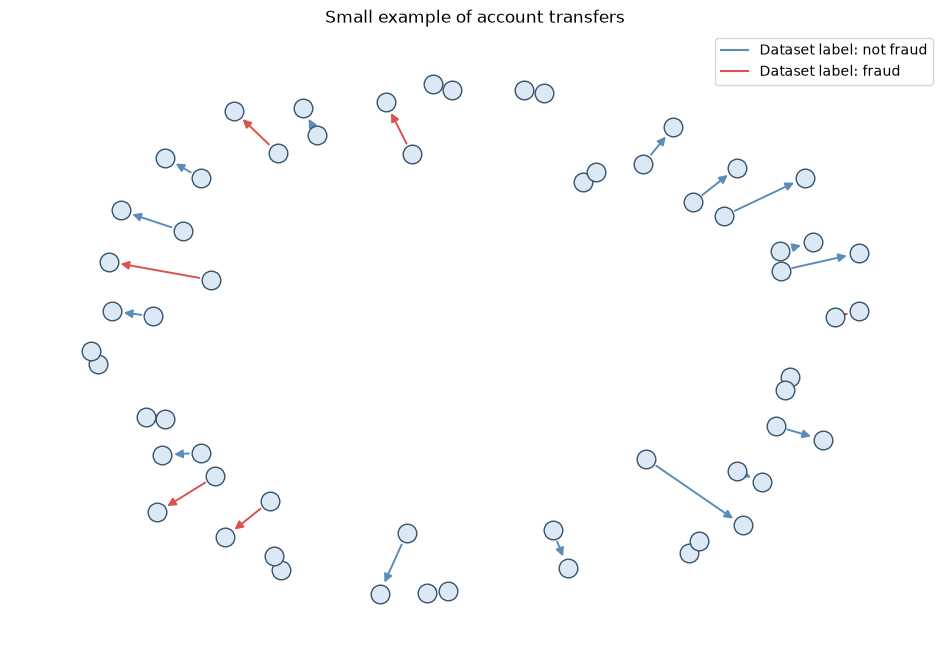

In [5]:
fraud_examples = transactions.loc[transactions["isFraud"] == 1].head(10)
normal_examples = transactions.loc[transactions["isFraud"] == 0].head(20)
visual_transactions = pd.concat([fraud_examples, normal_examples]).sort_index()
visual_graph = nx.from_pandas_edgelist(
    visual_transactions,
    source="nameOrig",
    target="nameDest",
    edge_attr=["isFraud"],
    create_using=nx.MultiDiGraph(),
)
positions = nx.spring_layout(visual_graph, seed=42)
edge_colors = [
    "#d9534f" if attributes["isFraud"] == 1 else "#5b8db8"
    for _, _, _, attributes in visual_graph.edges(keys=True, data=True)
]

plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(visual_graph, positions, node_size=180, node_color="#dce9f5", edgecolors="#35536f")
nx.draw_networkx_edges(visual_graph, positions, edge_color=edge_colors, arrows=True, arrowstyle="-|>", arrowsize=12, width=1.4)
plt.legend(handles=[
    Line2D([0], [0], color="#5b8db8", label="Dataset label: not fraud"),
    Line2D([0], [0], color="#d9534f", label="Dataset label: fraud"),
], loc="best")
plt.title("Small example of account transfers")
plt.axis("off")
plt.show()

## What we learned

- A transaction table can be represented as a graph: sender account → receiver account.
- Accounts are nodes; transactions are directed edges with amount, type, and step information.
- In-degree, out-degree, and amount totals summarize how connected and active an account is.
- This small graph teaches the structure. For the model, we will build historical account features without using future transactions or the `isFraud` answer as an input.